  # LLM-as-a-Judge Prompt Engineering for English-to-Mandarin Translation

## Objective

Investigate prompt-engineering techniques that improve the consistency and
reliability of LLM-as-a-Judge evaluations for English-to-Mandarin translation.

### Experiment Goals

- Establish a baseline evaluation prompt.
- Design multiple prompt-engineering approaches.
- Evaluate representative English-to-Mandarin translations.
- Run each prompt configuration repeatedly.
- Measure score consistency and output reliability.
- Compare prompt configurations.
- Recommend a prompt structure based on experimental evidence.

In [ ]:
!pip install -q datasets

In [ ]:
import json
import random
from pathlib import Path
from datasets import load_dataset

import numpy as np
import pandas as pd

random.seed(42)
np.random.seed(42)

#inital config

NUM_REPEATED_RUNS = 5
SCORE_MIN = 1
SCORE_MAX = 5

print(f"Repeated judge runs: {NUM_REPEATED_RUNS}")
print(f"Score range: {SCORE_MIN}-{SCORE_MAX}")



Repeated judge runs: 5
Score range: 1-5


In [ ]:
dataset=load_dataset("wmt/wmt17","zh-en",split="test")
print(dataset)

Dataset({
    features: ['translation'],
    num_rows: 2001
})


In [ ]:
dataset[0]

{'translation': {'en': '28-Year-Old Chef Found Dead at San Francisco Mall',
  'zh': '28岁厨师被发现死于旧金山一家商场'}}

In [ ]:
from datasets.features import translation
dataset[0]["translation"]["en"]

'28-Year-Old Chef Found Dead at San Francisco Mall'

In [ ]:
row=[]
for i,examples in enumerate(dataset):
  translation=examples["translation"]
  row.append({
      "id": f"WMT17_{i:04d}",
      "source_en": translation["en"],
      "reference_zh": translation["zh"]
  })


df=pd.DataFrame(row)
print("Number of exampls:", len(df))
df.head(10)

Number of exampls: 2001


,id,source_en,reference_zh
0,WMT17_0000,28-Year-Old Chef Found Dead at San Francisco Mall,28岁厨师被发现死于旧金山一家商场
1,WMT17_0001,A 28-year-old chef who had recently moved to S...,近日刚搬至旧金山的一位28岁厨师本周被发现死于当地一家商场的楼梯间。
2,WMT17_0002,But the victim's brother says he can't think o...,但受害人的哥哥表示想不出有谁会想要加害于他，并称“一切终于好起来了。”
3,WMT17_0003,The body found at the Westfield Mall Wednesday...,旧金山验尸官办公室表示，周三早上于西田购物中心发现的尸体确认为28岁旧金山居民 Frank ...
4,WMT17_0004,The San Francisco Police Department said the d...,旧金山警察局称该起死亡案件被裁定为他杀，并正在进行调查。
5,WMT17_0005,"The victim's brother, Louis Galicia, told ABC ...",受害人的哥哥 Louis Galicia 对美国广播公司位于旧金山的电台 KGO 表示，之前...
6,WMT17_0006,A spokesperson for Sons & Daughters said they ...,Sons & Daughters 餐馆的一位发言人表示，他们对于 Frank 的死感到“非常...
7,WMT17_0007,"""We are a small team that operates like a clos...",该发言人称，“我们是相处得像亲密无间的一家人的一个小团队，我们将深深怀念他。”
8,WMT17_0008,Our thoughts and condolences are with Frank's ...,在这个悲痛的时刻，我们向 Frank 的家人及朋友表达我们深切的同情与哀悼。
9,WMT17_0009,Louis Galicia said Frank initially stayed in h...,Louis Galicia 称 Frank 起初住在招待所里，但是最近“一切终于好起来了。”


In [ ]:
df=df.dropna(subset=["source_en","reference_zh"])
print("Number of exampls:", len(df))
df["source_en"]=df["source_en"].str.strip()
df["reference_zh"]=df["reference_zh"].str.strip()
df=df[(df['source_en']!="")& (df['reference_zh']!="")]

df=df.drop_duplicates(subset=["source_en","reference_zh"]).reset_index(drop=True)
print("Number of exampls:", len(df))


df



Number of exampls: 2001
Number of exampls: 2001


,id,source_en,reference_zh
0,WMT17_0000,28-Year-Old Chef Found Dead at San Francisco Mall,28岁厨师被发现死于旧金山一家商场
1,WMT17_0001,A 28-year-old chef who had recently moved to S...,近日刚搬至旧金山的一位28岁厨师本周被发现死于当地一家商场的楼梯间。
2,WMT17_0002,But the victim's brother says he can't think o...,但受害人的哥哥表示想不出有谁会想要加害于他，并称“一切终于好起来了。”
3,WMT17_0003,The body found at the Westfield Mall Wednesday...,旧金山验尸官办公室表示，周三早上于西田购物中心发现的尸体确认为28岁旧金山居民 Frank ...
4,WMT17_0004,The San Francisco Police Department said the d...,旧金山警察局称该起死亡案件被裁定为他杀，并正在进行调查。
...,...,...,...
1996,WMT17_1996,A domestic brokerage analyst said that the Ori...,国内一家券商分析师表示，东方证券在港基础并不算好，旗下资管业务才是东证所长。相比中银国际、中...
1997,WMT17_1997,Experts pointed out that with the return of th...,专家指出，今年以来随着证券市场回归平淡，很多券商业绩都出现了下滑，但公司上市之后情况要更多看...
1998,WMT17_1998,After the introduction of the regulation of th...,此项调控新政出台后，苏州将成为全国第一个重启限购的二线城市。
1999,WMT17_1999,"In addition to Suzhou, other second-tier citie...",出台或者即将出台楼市调控政策的二线城市不止苏州，还包括合肥、南京等城市。


In [ ]:
N_EXAMPLES= 50
SEED=42

eval_df=df.sample(n=N_EXAMPLES,random_state=SEED).reset_index(drop=True)
eval_df["eval_id"] = [
    f"E{i+1:03d}"
    for i in range(len(eval_df))
]

eval_df = eval_df[
    ["eval_id", "source_en", "reference_zh"]
]

print("Evaluation examples:", len(eval_df))

eval_df.head(10)


Evaluation examples: 50


,eval_id,source_en,reference_zh
0,E001,Democratic members of the House Intelligence C...,众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。
1,E002,"Russian gymnast Aliya Mustafina, with her larg...",长着一双会说话的大眼睛的俄罗斯体操选手穆斯塔芬娜 (Aliya Mustafina) 被指长...
2,E003,Gee and Schwartzman are scheduled to discuss a...,吉和斯瓦茨曼将讨论并分享1926年贝特伦·古德西的设计图片以及1933年哈迪・霍尔兹曼・弗夫...
3,E004,"Over the past decade, the State Council has is...",近十年来，国务院前后共发布过5次淘汰过剩与落后产能的通知。
4,E005,Helen Glover and Heather Stanning inspired to ...,海伦·格拉芙和希瑟·斯坦宁受身患癌症的教练的鼓舞，夺得赛艇金牌
5,E006,12-0 and GB had hardly touched the ball.,12比0，英国队几乎没有碰到过球。
6,E007,"According to the navigation needs, the old Wan...","根据通航需要,老万福河航道采取养护改造的方式,对局部水深进行了浚深,局部急弯进行裁弯取直等,..."
7,E008,Even though she learns and works in decentrali...,即便通过分散的，模块化的时间来学习和工作，她也基本上都可以完成任务，并取得不错的成绩。
8,E009,"""Tourists that way, tomatoes back here,"" as a ...",莫斯科报纸 Vedemosti 的一篇报道称：“游客去了，番茄回来了。”
9,E010,According to the forecast of Ministry of Trade...,根据塔贸易和经济发展部的预测，2016年塔国的经济增长将达到7%，而国家的通胀也基本是在这一...


In [ ]:
for i in range(5):
    print("=" * 80)
    print("ID:", eval_df.loc[i, "eval_id"])
    print()
    print("ENGLISH:")
    print(eval_df.loc[i, "source_en"])
    print()
    print("MANDARIN REFERENCE:")
    print(eval_df.loc[i, "reference_zh"])
    print()

ID: E001

ENGLISH:
Democratic members of the House Intelligence Committee released their own findings on Thursday that agreed with some of the conclusions of the Republican task force.

MANDARIN REFERENCE:
众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。

ID: E002

ENGLISH:
Russian gymnast Aliya Mustafina, with her large, expressive eyes, has been said to be a dead ringer for Cuban-American singer Gloria Estefan.

MANDARIN REFERENCE:
长着一双会说话的大眼睛的俄罗斯体操选手穆斯塔芬娜 (Aliya Mustafina) 被指长相酷似古巴裔美国歌星格洛丽亚·埃斯特凡 (Gloria Estefan)。

ID: E003

ENGLISH:
Gee and Schwartzman are scheduled to discuss and share images of the 1926 Bertram Goodhue design as well as the 1993 restoration and addition by Hardy Holzman Pfeiffer Associates.

MANDARIN REFERENCE:
吉和斯瓦茨曼将讨论并分享1926年贝特伦·古德西的设计图片以及1933年哈迪・霍尔兹曼・弗夫尔事务所的修复与扩建图片。

ID: E004

ENGLISH:
Over the past decade, the State Council has issued a total of five notices for the elimination of excessive and backward production capacity.

MANDARIN REFERENCE:
近十年来，国务院前后共发布过5次淘

In [ ]:
!pip install -q transformers sentencepiece sacremoses

In [ ]:
from transformers import AutoTokenizer,AutoModelForSeq2SeqLM

model_name="Helsinki-NLP/opus-mt-en-zh"
tokenizer=AutoTokenizer.from_pretrained(model_name)
model=AutoModelForSeq2SeqLM.from_pretrained(model_name)


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

In [ ]:
def translate_en_to_zh(text):

  input=tokenizer(text,return_tensors="pt")
  output=model.generate(**input)
  translation_1=tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

  return(translation_1)


In [ ]:
eval_df.head()

,eval_id,source_en,reference_zh
0,E001,Democratic members of the House Intelligence C...,众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。
1,E002,"Russian gymnast Aliya Mustafina, with her larg...",长着一双会说话的大眼睛的俄罗斯体操选手穆斯塔芬娜 (Aliya Mustafina) 被指长...
2,E003,Gee and Schwartzman are scheduled to discuss a...,吉和斯瓦茨曼将讨论并分享1926年贝特伦·古德西的设计图片以及1933年哈迪・霍尔兹曼・弗夫...
3,E004,"Over the past decade, the State Council has is...",近十年来，国务院前后共发布过5次淘汰过剩与落后产能的通知。
4,E005,Helen Glover and Heather Stanning inspired to ...,海伦·格拉芙和希瑟·斯坦宁受身患癌症的教练的鼓舞，夺得赛艇金牌


In [ ]:
test_source = eval_df.loc[0,"source_en"]

candidate = translate_en_to_zh(test_source)

print("ENGLISH SOURCE:")
print(test_source)

print("\nMODEL TRANSLATION:")
print(candidate)

print("\nWMT17 REFERENCE:")
print(eval_df.loc[0, "reference_zh"])

ENGLISH SOURCE:
Democratic members of the House Intelligence Committee released their own findings on Thursday that agreed with some of the conclusions of the Republican task force.

MODEL TRANSLATION:
众议院情报委员会的民主成员在星期四公布了他们自己的调查结果,他们同意共和党工作队的一些结论。

WMT17 REFERENCE:
众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。


In [ ]:
candidate_tranlation=[]

for i,row in eval_df.iterrows():
  candidate=translate_en_to_zh(row["source_en"])
  candidate_tranlation.append(candidate)

  print(f"translated {i+1}/{len(eval_df)}")

eval_df["candidate_zh"]=candidate_tranlation
eval_df.head()

translated 1/50
translated 2/50
translated 3/50
translated 4/50
translated 5/50
translated 6/50
translated 7/50
translated 8/50
translated 9/50
translated 10/50
translated 11/50
translated 12/50
translated 13/50
translated 14/50
translated 15/50
translated 16/50
translated 17/50
translated 18/50
translated 19/50
translated 20/50
translated 21/50
translated 22/50
translated 23/50
translated 24/50
translated 25/50
translated 26/50
translated 27/50
translated 28/50
translated 29/50
translated 30/50
translated 31/50
translated 32/50
translated 33/50
translated 34/50
translated 35/50
translated 36/50
translated 37/50
translated 38/50
translated 39/50
translated 40/50
translated 41/50
translated 42/50
translated 43/50
translated 44/50
translated 45/50
translated 46/50
translated 47/50
translated 48/50
translated 49/50
translated 50/50


,eval_id,source_en,reference_zh,candidate_zh
0,E001,Democratic members of the House Intelligence C...,众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。,"众议院情报委员会的民主成员在星期四公布了他们自己的调查结果,他们同意共和党工作队的一些结论。"
1,E002,"Russian gymnast Aliya Mustafina, with her larg...",长着一双会说话的大眼睛的俄罗斯体操选手穆斯塔芬娜 (Aliya Mustafina) 被指长...,"俄罗斯体育馆Aliya Mustafina, 以她大眼睛的表情, 据说是古巴裔美国人歌手Gl..."
2,E003,Gee and Schwartzman are scheduled to discuss a...,吉和斯瓦茨曼将讨论并分享1926年贝特伦·古德西的设计图片以及1933年哈迪・霍尔兹曼・弗夫...,Gee和Schwartzman计划讨论和分享Bertram Goodhue 1926年设计以...
3,E004,"Over the past decade, the State Council has is...",近十年来，国务院前后共发布过5次淘汰过剩与落后产能的通知。,"过去十年来,国务院共发出五份消除过度和落后生产能力的通知。"
4,E005,Helen Glover and Heather Stanning inspired to ...,海伦·格拉芙和希瑟·斯坦宁受身患癌症的教练的鼓舞，夺得赛艇金牌,Helen Glover和Heather Stanning在教练的癌症战役中 获得了划划船胜...


In [ ]:
print(eval_df["candidate_zh"].isna().sum())
print(eval_df["candidate_zh"].isnull().sum())
(eval_df["candidate_zh"].str.strip() == "").sum()

assert eval_df["candidate_zh"].notna().all()
assert eval_df["candidate_zh"].notnull().all()
assert (eval_df["candidate_zh"].str.strip() != "").all()



0
0


In [ ]:
#saving to csv
eval_df.to_csv("wmt17_en_zh_judge_eval_50.csv",
                index=False, encoding="utf-8-sig")

# LLM-as-a-Judge Prompt Engineering Experiments

In [ ]:
P0_BASELINE = """
You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
{source}

Reference Mandarin translation:
{reference}

Candidate Mandarin translation:
{candidate}

Evaluate the overall quality of the candidate translation compared with the
English source and reference translation.

Give an overall score from 1 to 5:

1 = Very poor
2 = Poor
3 = Acceptable
4 = Good
5 = Excellent

Return your answer exactly in this format:

Score: <1-5>
Explanation: <brief explanation>
""".strip()

In [ ]:
example=eval_df.iloc[0]
baseline_test=P0_BASELINE.format(
    source=example['source_en'],
    reference=example['reference_zh'],
    candidate=example['candidate_zh']
    )

print(baseline_test)

You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
Democratic members of the House Intelligence Committee released their own findings on Thursday that agreed with some of the conclusions of the Republican task force.

Reference Mandarin translation:
众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。

Candidate Mandarin translation:
众议院情报委员会的民主成员在星期四公布了他们自己的调查结果,他们同意共和党工作队的一些结论。

Evaluate the overall quality of the candidate translation compared with the
English source and reference translation.

Give an overall score from 1 to 5:

1 = Very poor
2 = Poor
3 = Acceptable
4 = Good
5 = Excellent

Return your answer exactly in this format:

Score: <1-5>
Explanation: <brief explanation>


## P1 — Explicit Evaluation Rubric

### Technique
Explicit rubric prompting.

### Hypothesis
Providing clearly defined translation-quality dimensions will reduce ambiguity
in the evaluation process and improve score consistency across repeated judge
runs.

### Evaluation dimensions
- Accuracy
- Completeness
- Fluency
- Terminology

In [ ]:
P1_RUBRIC = """
You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
{source}

Reference Mandarin translation:
{reference}

Candidate Mandarin translation:
{candidate}

Evaluate the candidate translation using the following criteria:

Accuracy:
Does the candidate correctly preserve the meaning of the English source?

Completeness:
Does the candidate preserve all important information without omissions
or unsupported additions?

Fluency:
Is the Mandarin grammatically correct, natural, and readable?

Terminology:
Are words, expressions, names, and domain-specific terms translated
appropriately?

Based on these criteria, give one overall score from 1 to 5:

1 = Very poor
2 = Poor
3 = Acceptable
4 = Good
5 = Excellent

Return your answer exactly in this format:

Score: <1-5>
Explanation: <brief explanation>
""".strip()

In [ ]:
example=eval_df.iloc[0]

p1_test=P1_RUBRIC.format(
    source=example['source_en'],
    reference=example['reference_zh'],
    candidate=example['candidate_zh']
    )

print(p1_test)


You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
Democratic members of the House Intelligence Committee released their own findings on Thursday that agreed with some of the conclusions of the Republican task force.

Reference Mandarin translation:
众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。

Candidate Mandarin translation:
众议院情报委员会的民主成员在星期四公布了他们自己的调查结果,他们同意共和党工作队的一些结论。

Evaluate the candidate translation using the following criteria:

Accuracy:
Does the candidate correctly preserve the meaning of the English source?

Completeness:
Does the candidate preserve all important information without omissions
or unsupported additions?

Fluency:
Is the Mandarin grammatically correct, natural, and readable?

Terminology:
Are words, expressions, names, and domain-specific terms translated
appropriately?

Based on these criteria, give one overall score from 1 to 5:

1 = Very poor
2 = Poor
3 = Acceptable
4 = Good
5 = Excellent

Return your answer exac

In [ ]:
PROMPTS = {
    "P0_baseline": P0_BASELINE,
    "P1_rubric": P1_RUBRIC
}

print("Current prompt configurations:")

for name in PROMPTS:
    print("-", name)

Current prompt configurations:
- P0_baseline
- P1_rubric


## P2 — Anchored Scoring Rubric

### Technique
Explicit evaluation rubric with detailed score anchors.

### Hypothesis
Providing precise definitions for each score level will reduce ambiguity between
adjacent scores and improve consistency across repeated judge runs.

P2 retains the evaluation dimensions introduced in P1 and adds explicit
quality definitions for scores 1–5.

In [ ]:
P2_ANCHORED = """
You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
{source}

Reference Mandarin translation:
{reference}

Candidate Mandarin translation:
{candidate}

Evaluate the candidate translation using the following criteria:

Accuracy:
Does the candidate correctly preserve the meaning of the English source?

Completeness:
Does the candidate preserve all important information without omissions
or unsupported additions?

Fluency:
Is the Mandarin grammatically correct, natural, and readable?

Terminology:
Are words, expressions, names, and domain-specific terms translated
appropriately?

Based on these criteria, give one overall score from 1 to 5 using the
following scoring anchors:

5 = Excellent
The meaning is fully preserved. There are no meaningful mistranslations,
omissions, or unsupported additions. The Mandarin is natural and fluent,
and terminology is appropriate.

4 = Good
The meaning is substantially preserved. There may be minor translation,
fluency, or terminology issues, but they do not materially change the
meaning of the source.

3 = Acceptable
The main meaning is preserved, but there are noticeable errors, omissions,
additions, terminology problems, or fluency issues that reduce translation
quality.

2 = Poor
There are major translation problems. Important information is mistranslated,
omitted, or incorrectly added, although some of the source meaning remains.

1 = Very poor
The translation substantially fails to convey the meaning of the source,
contains severe errors, or is largely unusable.

Return your answer exactly in this format:

Score: <1-5>
Explanation: <brief explanation>
""".strip()

In [ ]:
example = eval_df.iloc[0]

p2_test = P2_ANCHORED.format(
    source=example["source_en"],
    reference=example["reference_zh"],
    candidate=example["candidate_zh"]
)

print(p2_test)

You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
Democratic members of the House Intelligence Committee released their own findings on Thursday that agreed with some of the conclusions of the Republican task force.

Reference Mandarin translation:
众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。

Candidate Mandarin translation:
众议院情报委员会的民主成员在星期四公布了他们自己的调查结果,他们同意共和党工作队的一些结论。

Evaluate the candidate translation using the following criteria:

Accuracy:
Does the candidate correctly preserve the meaning of the English source?

Completeness:
Does the candidate preserve all important information without omissions
or unsupported additions?

Fluency:
Is the Mandarin grammatically correct, natural, and readable?

Terminology:
Are words, expressions, names, and domain-specific terms translated
appropriately?

Based on these criteria, give one overall score from 1 to 5 using the
following scoring anchors:

5 = Excellent
The meaning is fully preserved. The

## P3 — Decomposed Evaluation with Structured Output

### Technique
Decomposed evaluation with dimension-level scoring and structured output.

### Hypothesis
Requiring the judge to evaluate accuracy, completeness, fluency, and terminology
individually before assigning an overall score will encourage a more systematic
evaluation process and improve consistency across repeated runs.

Structured output is also expected to improve output-format reliability.

In [ ]:
P3_DECOMPOSED = """
You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
{source}

Reference Mandarin translation:
{reference}

Candidate Mandarin translation:
{candidate}

Evaluate the candidate translation using the following four dimensions:

Accuracy:
Does the candidate correctly preserve the meaning of the English source?

Completeness:
Does the candidate preserve all important information without omissions
or unsupported additions?

Fluency:
Is the Mandarin grammatically correct, natural, and readable?

Terminology:
Are words, expressions, names, and domain-specific terms translated
appropriately?

Score each dimension independently from 1 to 5 using the following scale:

5 = Excellent
4 = Good
3 = Acceptable
2 = Poor
1 = Very poor

After evaluating all four dimensions, assign an overall translation-quality
score from 1 to 5.

The overall score should reflect the translation as a whole and should not
simply be calculated as the arithmetic mean of the four dimension scores.

Return valid JSON only using exactly this structure:

{{
  "accuracy": <1-5>,
  "completeness": <1-5>,
  "fluency": <1-5>,
  "terminology": <1-5>,
  "overall": <1-5>,
  "explanation": "<brief explanation>"
}}
""".strip()

In [ ]:
example = eval_df.iloc[0]

p3_test = P3_DECOMPOSED.format(
    source=example["source_en"],
    reference=example["reference_zh"],
    candidate=example["candidate_zh"]
)

print(p3_test)

You are evaluating the quality of an English-to-Mandarin Chinese translation.

English source:
Democratic members of the House Intelligence Committee released their own findings on Thursday that agreed with some of the conclusions of the Republican task force.

Reference Mandarin translation:
众议院情报委员会的民主党成员于周四公布了其调查结果，与共和党专项工作小组的部分结论相一致。

Candidate Mandarin translation:
众议院情报委员会的民主成员在星期四公布了他们自己的调查结果,他们同意共和党工作队的一些结论。

Evaluate the candidate translation using the following four dimensions:

Accuracy:
Does the candidate correctly preserve the meaning of the English source?

Completeness:
Does the candidate preserve all important information without omissions
or unsupported additions?

Fluency:
Is the Mandarin grammatically correct, natural, and readable?

Terminology:
Are words, expressions, names, and domain-specific terms translated
appropriately?

Score each dimension independently from 1 to 5 using the following scale:

5 = Excellent
4 = Good
3 = Acceptable
2 = Poor
1 = Very poor

Aft

In [ ]:
PROMPTS = {
    "P0_baseline": P0_BASELINE,
    "P1_rubric": P1_RUBRIC,
    "P2_anchored": P2_ANCHORED,
    "P3_decomposed": P3_DECOMPOSED
}

print("Current prompt configurations:")

for name in PROMPTS:
    print("-", name)

Current prompt configurations:
- P0_baseline
- P1_rubric
- P2_anchored
- P3_decomposed


# Judge Model Setup

In [ ]:
import torch

print("pytorch version", torch.__version__)
print("cuda available",torch.cuda.is_available())



pytorch version 2.11.0+cu130
cuda available True


In [ ]:
!pip install transformers accelerate -q

In [ ]:
from transformers import AutoTokenizer,AutoModelForCausalLM
import torch

JUDGE_MODE_NAME="Qwen/Qwen3-4B"

jude_tokenizer=AutoTokenizer.from_pretrained(JUDGE_MODE_NAME)
judge_model=AutoModelForCausalLM.from_pretrained(JUDGE_MODE_NAME,torch_dtype="auto",device_map="auto")
judge_model.eval()

print("judge model loaded")
print(JUDGE_MODE_NAME)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

judge model loaded
Qwen/Qwen3-4B


In [ ]:
print(PROMPTS)

{'P0_baseline': 'You are evaluating the quality of an English-to-Mandarin Chinese translation.\n\nEnglish source:\n{source}\n\nReference Mandarin translation:\n{reference}\n\nCandidate Mandarin translation:\n{candidate}\n\nEvaluate the overall quality of the candidate translation compared with the\nEnglish source and reference translation.\n\nGive an overall score from 1 to 5:\n\n1 = Very poor\n2 = Poor\n3 = Acceptable\n4 = Good\n5 = Excellent\n\nReturn your answer exactly in this format:\n\nScore: <1-5>\nExplanation: <brief explanation>', 'P1_rubric': 'You are evaluating the quality of an English-to-Mandarin Chinese translation.\n\nEnglish source:\n{source}\n\nReference Mandarin translation:\n{reference}\n\nCandidate Mandarin translation:\n{candidate}\n\nEvaluate the candidate translation using the following criteria:\n\nAccuracy:\nDoes the candidate correctly preserve the meaning of the English source?\n\nCompleteness:\nDoes the candidate preserve all important information without om

In [ ]:
def run_judge(
    prompt,
    temperature=0.7,
    top_p=0.95,
    max_new_tokens=256
):
    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = jude_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = jude_tokenizer(
        text,
        return_tensors="pt"
    ).to(judge_model.device)

    with torch.no_grad():
        output = judge_model.generate(
            **inputs,
            do_sample=True,
            temperature=temperature,
            top_p=top_p,
            max_new_tokens=max_new_tokens,
            pad_token_id=jude_tokenizer.eos_token_id
        )

    generated_tokens = output[0][inputs["input_ids"].shape[1]:]

    response = jude_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [ ]:
example=eval_df.loc[0]
P0_prompt=P0_BASELINE.format(
    source=example["source_en"],
    reference=example["reference_zh"],
    candidate=example["candidate_zh"]
)

for run in range(NUM_REPEATED_RUNS):

    response = run_judge(P0_prompt)

    print("=" * 70)
    print(f"RUN {run + 1}")
    print(response)
    print()

RUN 1
Score: 4  
Explanation: The candidate translation is clear and accurate, conveying the same meaning as the source and reference. It uses natural Mandarin and maintains the key information. The only minor difference is the use of "民主成员" instead of "民主党成员," which is still understandable and does not affect the overall quality.

RUN 2
Score: 4
Explanation: The candidate translation is clear and accurate, conveying the same meaning as the source and reference. It uses natural Mandarin and maintains the key information. The only minor difference is the use of "民主成员" instead of "民主党成员," which is acceptable as both are correct but "民主党成员" is more commonly used in formal contexts. Overall, it is a good translation.

RUN 3
Score: 4  
Explanation: The candidate translation is clear and accurate, closely reflecting the original English source. It correctly conveys the main points about the Democratic members releasing their findings and agreeing with some conclusions of the Republican task 

In [ ]:
import re, json

JUDGE_CONFIG = {
    "model": JUDGE_MODE_NAME,
    "temperature": 0.7,
    "top_p": 0.95,
    "max_new_tokens_standard": 128,
    "max_new_tokens_p3": 256,
    "repeated_runs": NUM_REPEATED_RUNS,
    "num_examples": len(eval_df),
    "seed": SEED,
}

print("Judge experiment configuration")
print("-" * 50)
for k, v in JUDGE_CONFIG.items():
    print(f"{k}: {v}")


def _extract_json(text):
    """Strip markdown fences and pull the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text)
    text = text.replace("```", "").strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    if not m:
        return None
    try:
        return json.loads(m.group(0))
    except json.JSONDecodeError:
        return None


def parse_judge_response(response, prompt_name):
    result = {
        "score": None, "accuracy": None, "completeness": None,
        "fluency": None, "terminology": None,
        "explanation": None, "valid_output": False,
    }

    if prompt_name == "P3_decomposed":
        data = _extract_json(response)
        if isinstance(data, dict):
            result["accuracy"]      = data.get("accuracy")
            result["completeness"]  = data.get("completeness")
            result["fluency"]       = data.get("fluency")
            result["terminology"]   = data.get("terminology")
            result["score"]         = data.get("overall")
            result["explanation"]   = data.get("explanation")

            dims = [result["accuracy"], result["completeness"],
                    result["fluency"], result["terminology"], result["score"]]
            result["valid_output"] = all(
                isinstance(v, int) and 1 <= v <= 5 for v in dims
            )
    else:
        score_match = re.search(r"Score:\s*([1-5])", response, re.IGNORECASE)
        expl_match  = re.search(r"Explanation:\s*(.*)", response,
                                re.IGNORECASE | re.DOTALL)
        if score_match:
            result["score"] = int(score_match.group(1))
            result["valid_output"] = True
        if expl_match:
            result["explanation"] = expl_match.group(1).strip()

    return result

Judge experiment configuration
--------------------------------------------------
model: Qwen/Qwen3-4B
temperature: 0.7
top_p: 0.95
max_new_tokens_standard: 128
max_new_tokens_p3: 256
repeated_runs: 5
num_examples: 50
seed: 42


In [ ]:
example = eval_df.iloc[0]

for prompt_name, prompt_template in PROMPTS.items():

    prompt = prompt_template.format(
        source=example["source_en"],
        reference=example["reference_zh"],
        candidate=example["candidate_zh"]
    )

    max_tokens = (
        JUDGE_CONFIG["max_new_tokens_p3"]
        if prompt_name == "P3_decomposed"
        else JUDGE_CONFIG["max_new_tokens_standard"]
    )

    response = run_judge(
        prompt,
        temperature=JUDGE_CONFIG["temperature"],
        top_p=JUDGE_CONFIG["top_p"],
        max_new_tokens=max_tokens
    )

    parsed = parse_judge_response(
        response,
        prompt_name
    )

    print("=" * 80)
    print("PROMPT:", prompt_name)
    print("SCORE:", parsed["score"])
    print("VALID OUTPUT:", parsed["valid_output"])

    if prompt_name == "P3_decomposed":
        print("Accuracy:", parsed["accuracy"])
        print("Completeness:", parsed["completeness"])
        print("Fluency:", parsed["fluency"])
        print("Terminology:", parsed["terminology"])

    print()

PROMPT: P0_baseline
SCORE: 4
VALID OUTPUT: True

PROMPT: P1_rubric
SCORE: 4
VALID OUTPUT: True

PROMPT: P2_anchored
SCORE: 4
VALID OUTPUT: True

PROMPT: P3_decomposed
SCORE: 5
VALID OUTPUT: True
Accuracy: 5
Completeness: 5
Fluency: 5
Terminology: 5



# Repeated-Run Consistency Experiment

## Experimental Controls

The following variables are held constant across prompt configurations:

- Judge model: Qwen3-4B
- Evaluation dataset: 50 fixed WMT17 English-to-Chinese examples
- Candidate translations: fixed Helsinki-NLP translations
- Temperature: 0.7
- Top-p: 0.95
- Repeated evaluations: 5
- Reference translation availability: identical across prompts

The independent variable is the judge prompt structure.

## Primary Measurements

- Repeated-run score agreement
- Score standard deviation
- Score range
- Output-format compliance

A five-example pilot is performed before the full experiment.

In [ ]:
pilot_df = eval_df.head(5).copy()

PILOT_TOTAL = (
    len(pilot_df)
    * len(PROMPTS)
    * NUM_REPEATED_RUNS
)

print("Pilot examples:", len(pilot_df))
print("Prompt configurations:", len(PROMPTS))
print("Runs per configuration:", NUM_REPEATED_RUNS)
print("Total pilot evaluations:", PILOT_TOTAL)

Pilot examples: 5
Prompt configurations: 4
Runs per configuration: 5
Total pilot evaluations: 100


In [ ]:
from tqdm.auto import tqdm

pilot_results = []

progress = tqdm(total=PILOT_TOTAL)

for _, example in pilot_df.iterrows():

    for prompt_name, prompt_template in PROMPTS.items():

        prompt = prompt_template.format(
            source=example["source_en"],
            reference=example["reference_zh"],
            candidate=example["candidate_zh"]
        )

        max_tokens = (
            JUDGE_CONFIG["max_new_tokens_p3"]
            if prompt_name == "P3_decomposed"
            else JUDGE_CONFIG["max_new_tokens_standard"]
        )

        for run_number in range(1, NUM_REPEATED_RUNS + 1):

            response = run_judge(
                prompt,
                temperature=JUDGE_CONFIG["temperature"],
                top_p=JUDGE_CONFIG["top_p"],
                max_new_tokens=max_tokens
            )

            parsed = parse_judge_response(
                response,
                prompt_name
            )

            pilot_results.append({
                "eval_id": example["eval_id"],
                "prompt": prompt_name,
                "run": run_number,
                "score": parsed["score"],
                "accuracy": parsed["accuracy"],
                "completeness": parsed["completeness"],
                "fluency": parsed["fluency"],
                "terminology": parsed["terminology"],
                "valid_output": parsed["valid_output"],
                "explanation": parsed["explanation"],
                "raw_response": response
            })

            progress.update(1)

progress.close()

pilot_results_df = pd.DataFrame(pilot_results)

print("\nPilot complete.")
print("Results:", len(pilot_results_df))

  0%|          | 0/100 [00:00<?, ?it/s]


Pilot complete.
Results: 100


In [ ]:
print("Total evaluations:", len(pilot_results_df))

print(
    "Valid outputs:",
    pilot_results_df["valid_output"].sum()
)

print(
    "Invalid outputs:",
    (~pilot_results_df["valid_output"]).sum()
)

print(
    "Missing scores:",
    pilot_results_df["score"].isna().sum()
)

Total evaluations: 100
Valid outputs: 100
Invalid outputs: 0
Missing scores: 0


In [ ]:
pilot_compliance = (
    pilot_results_df
    .groupby("prompt")["valid_output"]
    .agg(["count", "sum", "mean"])
)

pilot_compliance["compliance_percent"] = (
    pilot_compliance["mean"] * 100
)

pilot_compliance

,count,sum,mean,compliance_percent
prompt,,,,
P0_baseline,25,25,1.0,100.0
P1_rubric,25,25,1.0,100.0
P2_anchored,25,25,1.0,100.0
P3_decomposed,25,25,1.0,100.0


In [ ]:
p3_failures = pilot_results_df[
    (pilot_results_df["prompt"] == "P3_decomposed") &
    (~pilot_results_df["valid_output"])
]

print("P3 failures:", len(p3_failures))

for _, row in p3_failures.iterrows():

    print("=" * 100)
    print("Example:", row["eval_id"])
    print("Run:", row["run"])
    print()
    print(row["raw_response"])
    print()

P3 failures: 0


In [ ]:
from tqdm.auto import tqdm

full_results = []
FULL_TOTAL = len(eval_df) * len(PROMPTS) * NUM_REPEATED_RUNS
print(f"Full run: {FULL_TOTAL} judge calls")

progress = tqdm(total=FULL_TOTAL)

for _, example in eval_df.iterrows():
    for prompt_name, template in PROMPTS.items():
        prompt = template.format(
            source=example["source_en"],
            reference=example["reference_zh"],
            candidate=example["candidate_zh"],
        )
        max_tokens = (JUDGE_CONFIG["max_new_tokens_p3"]
                      if prompt_name == "P3_decomposed"
                      else JUDGE_CONFIG["max_new_tokens_standard"])

        for run_number in range(1, NUM_REPEATED_RUNS + 1):
            response = run_judge(
                prompt,
                temperature=JUDGE_CONFIG["temperature"],
                top_p=JUDGE_CONFIG["top_p"],
                max_new_tokens=max_tokens,
            )
            parsed = parse_judge_response(response, prompt_name)

            full_results.append({
                "eval_id": example["eval_id"],
                "prompt": prompt_name,
                "run": run_number,
                "score": parsed["score"],
                "accuracy": parsed["accuracy"],
                "completeness": parsed["completeness"],
                "fluency": parsed["fluency"],
                "terminology": parsed["terminology"],
                "valid_output": parsed["valid_output"],
                "explanation": parsed["explanation"],
                "raw_response": response,
            })
            progress.update(1)

progress.close()

full_df = pd.DataFrame(full_results)
full_df.to_csv("judge_full_results.csv", index=False, encoding="utf-8-sig")
print(f"\nDone. {len(full_df)} rows saved to judge_full_results.csv")

Full run: 1000 judge calls


  0%|          | 0/1000 [00:00<?, ?it/s]


Done. 1000 rows saved to judge_full_results.csv


In [ ]:
print("=" * 70)
print("OUTPUT-FORMAT COMPLIANCE")
print("=" * 70)
compliance = full_df.groupby("prompt")["valid_output"].agg(
    n="count", n_valid="sum", rate="mean"
)
compliance["rate_pct"] = (compliance["rate"] * 100).round(1)
display(compliance)

print("\n" + "=" * 70)
print("MEAN OVERALL SCORE PER PROMPT")
print("=" * 70)
mean_scores = full_df.groupby("prompt")["score"].agg(
    mean="mean", std="std", n="count"
).round(3)
display(mean_scores)

OUTPUT-FORMAT COMPLIANCE


,n,n_valid,rate,rate_pct
prompt,,,,
P0_baseline,250,250,1.0,100.0
P1_rubric,250,250,1.0,100.0
P2_anchored,250,250,1.0,100.0
P3_decomposed,250,250,1.0,100.0



MEAN OVERALL SCORE PER PROMPT


,mean,std,n
prompt,,,
P0_baseline,3.848,0.402,250
P1_rubric,3.792,0.549,250
P2_anchored,3.804,0.488,250
P3_decomposed,3.912,1.010,250


In [ ]:
# Per (prompt, example) variance
consistency = full_df.groupby(["prompt", "eval_id"])["score"].agg(
    mean="mean", std="std", min="min", max="max", n="count"
).reset_index()
consistency["range"] = consistency["max"] - consistency["min"]
consistency["stable"] = consistency["std"].fillna(0) == 0

summary = consistency.groupby("prompt").agg(
    mean_std=("std", "mean"),
    mean_range=("range", "mean"),
    pct_stable=("stable", "mean"),
    n_examples=("eval_id", "nunique"),
).round(3)
summary["pct_stable"] = (summary["pct_stable"] * 100).round(1)


print("CONSISTENCY ACROSS 5 REPEATED RUNS (lower std/range = better)")
print("=" * 70)
display(summary)

CONSISTENCY ACROSS 5 REPEATED RUNS (lower std/range = better)


,mean_std,mean_range,pct_stable,n_examples
prompt,,,,
P0_baseline,0.060,0.12,88.0,50
P1_rubric,0.051,0.10,90.0,50
P2_anchored,0.027,0.06,94.0,50
P3_decomposed,0.069,0.14,86.0,50


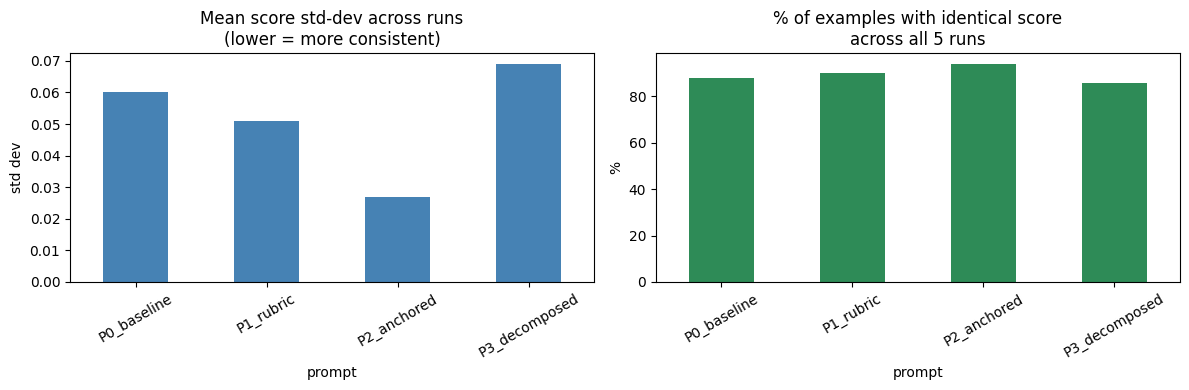

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

summary["mean_std"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Mean score std-dev across runs\n(lower = more consistent)")
axes[0].set_ylabel("std dev")
axes[0].tick_params(axis="x", rotation=30)

summary["pct_stable"].plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("% of examples with identical score\nacross all 5 runs")
axes[1].set_ylabel("%")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("consistency_summary.png", dpi=150)
plt.show()